# ❤️ Heart Disease Predictor — Neural Network (PyTorch)

This notebook trains a **feedforward neural network** using PyTorch to predict heart disease from 11 patient features.

**Dataset:** 918 patient records from `heart.csv`  
**Model:** 3-hidden-layer MLP with BatchNorm + Dropout  
**Final Accuracy:** ~89.67%

## 1. Imports

In [1]:
import pickle
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

RANDOM_STATE = 55
torch.manual_seed(RANDOM_STATE)
print('All imports OK')

All imports OK


## 2. Load & Inspect Dataset

In [2]:
df = pd.read_csv('heart.csv')
print(f'Dataset shape: {df.shape}')
df.head(10)

Dataset shape: (918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0
5,39,M,NAP,120,339,0,Normal,170,N,0.0,Up,0
6,45,F,ATA,130,237,0,Normal,170,N,0.0,Up,0
7,54,M,ATA,110,208,0,Normal,142,N,0.0,Up,0
8,37,M,ASY,140,207,0,Normal,130,Y,1.5,Flat,1
9,48,F,ATA,120,284,0,Normal,120,N,0.0,Up,0


In [3]:
# Class distribution
print('HeartDisease value counts:')
print(df['HeartDisease'].value_counts())
print(f'\nDisease proportion: {df["HeartDisease"].mean():.4f}')

HeartDisease value counts:
HeartDisease
1    508
0    410
Name: count, dtype: int64

Disease proportion: 0.5534


## 3. Preprocessing — One-Hot Encoding

The 5 categorical columns (`Sex`, `ChestPainType`, `RestingECG`, `ExerciseAngina`, `ST_Slope`) are converted to binary dummy columns using `pd.get_dummies()`.  
This expands the feature space from **12 → 20 columns** (excluding the target).

In [4]:
cat_variables = ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
df = pd.get_dummies(data=df, prefix=cat_variables, columns=cat_variables)

print(f'Columns after encoding: {len(df.columns)}')
df.head()

Columns after encoding: 21


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_F,Sex_M,ChestPainType_ASY,...,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST,ExerciseAngina_N,ExerciseAngina_Y,ST_Slope_Down,ST_Slope_Flat,ST_Slope_Up
0,40,140,289,0,172,0.0,0,False,True,False,...,False,False,False,True,False,True,False,False,False,True
1,49,160,180,0,156,1.0,1,True,False,False,...,True,False,False,True,False,True,False,False,True,False
2,37,130,283,0,98,0.0,0,False,True,False,...,False,False,False,False,True,True,False,False,False,True
3,48,138,214,0,108,1.5,1,True,False,True,...,False,False,False,True,False,False,True,False,True,False
4,54,150,195,0,122,0.0,0,False,True,False,...,True,False,False,True,False,True,False,False,False,True


## 4. Train / Test Split

In [5]:
FEATURE_NAMES = [x for x in df.columns if x != 'HeartDisease']
print(f'Number of features: {len(FEATURE_NAMES)}')

X = df[FEATURE_NAMES].values.astype(np.float32)
y = df['HeartDisease'].values.astype(np.float32)

X_train, X_val, y_train, y_val = train_test_split(
    X, y, train_size=0.8, random_state=RANDOM_STATE
)

print(f'Train samples : {len(X_train)}')
print(f'Test  samples : {len(X_val)}')
print(f'Target proportion (train): {y_train.mean():.4f}')

Number of features: 20
Train samples : 734
Test  samples : 184
Target proportion (train): 0.5518


## 5. Feature Scaling

Neural networks are sensitive to feature scale. Without normalisation, a feature like `RestingBP=140` would dominate over `Oldpeak=1.2` purely due to magnitude.  
`StandardScaler` transforms each feature to **mean=0, std=1**.  

> **Important:** `fit_transform` is called only on the training set. The test set is transformed using the same scaler (no data leakage).

In [6]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s   = scaler.transform(X_val)

# Convert to PyTorch tensors
X_train_t = torch.tensor(X_train_s, dtype=torch.float32)
y_train_t = torch.tensor(y_train,   dtype=torch.float32).unsqueeze(1)
X_val_t   = torch.tensor(X_val_s,   dtype=torch.float32)
y_val_t   = torch.tensor(y_val,     dtype=torch.float32).unsqueeze(1)

print('Tensors created.')
print(f'X_train_t shape: {X_train_t.shape}')
print(f'y_train_t shape: {y_train_t.shape}')

Tensors created.
X_train_t shape: torch.Size([734, 20])
y_train_t shape: torch.Size([734, 1])


## 6. Neural Network Architecture

```
Input (20 features)
    ↓
Linear(20 → 64) + BatchNorm + ReLU + Dropout(30%)
    ↓
Linear(64 → 32) + BatchNorm + ReLU + Dropout(20%)
    ↓
Linear(32 → 16) + ReLU
    ↓
Linear(16 → 1) + Sigmoid  →  probability (0–1)
```

| Component | Purpose |
|---|---|
| `Linear` | Learns weighted connections between neurons |
| `BatchNorm1d` | Normalises layer outputs — stabilises training |
| `ReLU` | Non-linear activation — lets the network learn complex patterns |
| `Dropout` | Randomly disables neurons during training — prevents overfitting |
| `Sigmoid` | Squashes output to 0–1 → interpreted as disease probability |

In [7]:
class HeartNet(nn.Module):
    def __init__(self, input_dim=20):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(32, 16),
            nn.ReLU(),

            nn.Linear(16, 1),
            nn.Sigmoid(),
        )

    def forward(self, x):
        return self.net(x)

model = HeartNet(input_dim=X_train_s.shape[1])
print(model)

HeartNet(
  (net): Sequential(
    (0): Linear(in_features=20, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=64, out_features=32, bias=True)
    (5): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=32, out_features=16, bias=True)
    (9): ReLU()
    (10): Linear(in_features=16, out_features=1, bias=True)
    (11): Sigmoid()
  )
)


## 7. Loss, Optimiser & Scheduler

| Component | Choice | Why |
|---|---|---|
| Loss | `BCELoss` | Binary Cross Entropy — standard for binary classification |
| Optimiser | `Adam` | Adaptive learning rate per parameter — fast and robust |
| `weight_decay` | `1e-4` | L2 regularisation — penalises large weights |
| Scheduler | `StepLR` | Halves learning rate every 100 epochs — fine-tunes later in training |

In [8]:
criterion = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=100, gamma=0.5)
print('Optimiser and scheduler ready.')

Optimiser and scheduler ready.


## 8. Training Loop

Each epoch:
1. **Forward pass** — data flows through all layers, produces a probability
2. **Loss** — how far off is the prediction from the real label
3. **Backpropagation** — calculates how much each weight contributed to the error
4. **Optimiser step** — nudges every weight to reduce the error
5. **Scheduler step** — adjusts learning rate

In [9]:
EPOCHS = 300
train_losses, val_losses, val_accs = [], [], []

for epoch in range(1, EPOCHS + 1):
    # --- Training ---
    model.train()
    optimizer.zero_grad()
    preds = model(X_train_t)
    loss  = criterion(preds, y_train_t)
    loss.backward()
    optimizer.step()
    scheduler.step()
    train_losses.append(loss.item())

    # --- Validation ---
    model.eval()
    with torch.no_grad():
        val_preds = model(X_val_t)
        val_loss  = criterion(val_preds, y_val_t).item()
        val_acc   = accuracy_score(y_val, (val_preds.numpy() > 0.5).astype(int))
    val_losses.append(val_loss)
    val_accs.append(val_acc)

    if epoch % 50 == 0:
        print(f'Epoch {epoch:3d} | Train Loss: {loss.item():.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}')

print('\nTraining complete.')

Epoch  50 | Train Loss: 0.4148 | Val Loss: 0.3913 | Val Acc: 0.8750
Epoch 100 | Train Loss: 0.2838 | Val Loss: 0.3257 | Val Acc: 0.8750
Epoch 150 | Train Loss: 0.2624 | Val Loss: 0.3279 | Val Acc: 0.8804
Epoch 200 | Train Loss: 0.2440 | Val Loss: 0.3359 | Val Acc: 0.8967
Epoch 250 | Train Loss: 0.2281 | Val Loss: 0.3427 | Val Acc: 0.8967
Epoch 300 | Train Loss: 0.2260 | Val Loss: 0.3492 | Val Acc: 0.8967

Training complete.


## 9. Training Curves

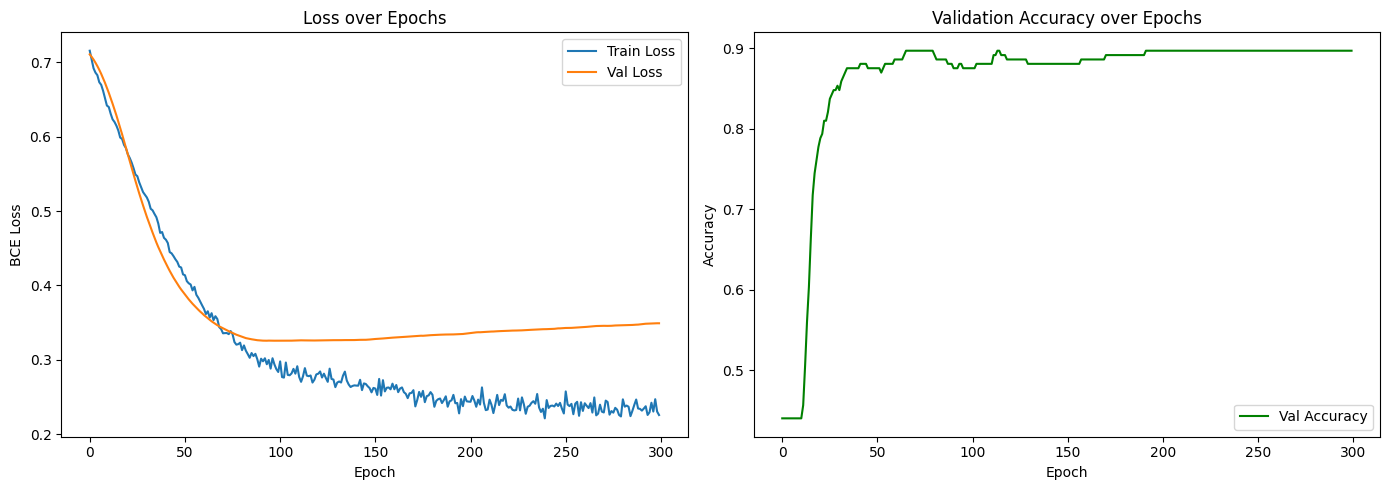

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(train_losses, label='Train Loss')
ax1.plot(val_losses,   label='Val Loss')
ax1.set_title('Loss over Epochs')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('BCE Loss')
ax1.legend()

ax2.plot(val_accs, color='green', label='Val Accuracy')
ax2.set_title('Validation Accuracy over Epochs')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.legend()

plt.tight_layout()
plt.show()

## 10. Final Evaluation

In [11]:
model.eval()
with torch.no_grad():
    val_probs = model(X_val_t).numpy().flatten()
    val_preds = (val_probs > 0.5).astype(int)

print('=' * 50)
print('NEURAL NETWORK ACCURACY ON TEST DATA')
print('=' * 50)
print(f'Accuracy: {accuracy_score(y_val, val_preds):.4f}')
print()
print(classification_report(y_val, val_preds, target_names=['No Disease', 'Disease']))

NEURAL NETWORK ACCURACY ON TEST DATA
Accuracy: 0.8967

              precision    recall  f1-score   support

  No Disease       0.90      0.86      0.88        81
     Disease       0.90      0.92      0.91       103

    accuracy                           0.90       184
   macro avg       0.90      0.89      0.89       184
weighted avg       0.90      0.90      0.90       184



In [12]:
cm = confusion_matrix(y_val, val_preds)
print('CONFUSION MATRIX')
print('=' * 50)
print(f'                Predicted No  Predicted Yes')
print(f'Actual No       {cm[0][0]:^13} {cm[0][1]:^13}')
print(f'Actual Yes      {cm[1][0]:^13} {cm[1][1]:^13}')

CONFUSION MATRIX
                Predicted No  Predicted Yes
Actual No            70            11      
Actual Yes            8            95      


## 11. Per-Sample Predictions (first 20 test rows)

In [13]:
results = pd.DataFrame({
    'Actual'  : y_val,
    'NN_Pred' : val_preds,
    'NN_Prob' : np.round(val_probs, 3)
})
results['Correct'] = (results['Actual'] == results['NN_Pred']).map({True: 'OK', False: 'WRONG'})
print(results.head(20).to_string())
print(f'\nTotal test samples: {len(X_val)}')
print(f'Correct predictions: {(y_val == val_preds).sum()} / {len(X_val)}')

    Actual  NN_Pred  NN_Prob Correct
0      0.0        0    0.002      OK
1      0.0        0    0.035      OK
2      0.0        0    0.144      OK
3      1.0        1    0.984      OK
4      1.0        1    0.998      OK
5      0.0        1    0.561   WRONG
6      0.0        0    0.003      OK
7      0.0        0    0.080      OK
8      1.0        1    0.975      OK
9      0.0        0    0.002      OK
10     0.0        0    0.004      OK
11     0.0        0    0.003      OK
12     1.0        1    0.512      OK
13     1.0        1    0.700      OK
14     0.0        0    0.005      OK
15     0.0        0    0.071      OK
16     0.0        0    0.021      OK
17     0.0        0    0.362      OK
18     1.0        1    0.618      OK
19     0.0        0    0.143      OK

Total test samples: 184
Correct predictions: 165 / 184


## 12. Save Model & Scaler

In [14]:
with open('nn_model.pkl', 'wb') as f:
    pickle.dump(model, f)

with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

print('Saved: nn_model.pkl and scaler.pkl')

Saved: nn_model.pkl and scaler.pkl


## 13. Single Prediction Example

Demonstrates how to use the saved model to predict for a new patient.

In [15]:
# Sample patient — expected: LOW RISK (row 0 from heart.csv)
# Age=40, Sex=M, ChestPainType=ATA, RestingBP=140, Cholesterol=289,
# FastingBS=0, RestingECG=Normal, MaxHR=172, ExerciseAngina=N, Oldpeak=0.0, ST_Slope=Up

sample = pd.DataFrame(0, index=[0], columns=FEATURE_NAMES)
sample['Age']                  = 40
sample['RestingBP']            = 140
sample['Cholesterol']          = 289
sample['FastingBS']            = 0
sample['MaxHR']                = 172
sample['Oldpeak']              = 0.0
sample['Sex_M']                = 1
sample['ChestPainType_ATA']    = 1
sample['RestingECG_Normal']    = 1
sample['ExerciseAngina_N']     = 1
sample['ST_Slope_Up']          = 1

scaled = scaler.transform(sample.values.astype(np.float32))
tensor = torch.tensor(scaled, dtype=torch.float32)

model.eval()
with torch.no_grad():
    prob = float(model(tensor).item())

print(f'Risk Probability : {prob * 100:.1f}%')
print(f'Prediction       : {"HIGH RISK" if prob > 0.5 else "LOW RISK"}')

Risk Probability : 0.5%
Prediction       : LOW RISK
